# kino.io.manga: reading real MaNGIA (TNG50 mock MaNGA) data

**This notebook replaces an earlier version** that worked around the lack of
a TNG-project API key by synthesising a fake "MaNGIA-shaped" cube and
reading it back. With a real key now in hand, this notebook uses **real
downloaded MaNGIA files** throughout, and the reader itself was rewritten
to match what MaNGIA actually is -- see `kino/io/manga.py`'s module
docstring for the full story. In short: MaNGIA (Sarmiento et al. 2022) is
**not** released as a single flux datacube. It ships as two different
products:

- **"maps"**: already spatially gridded, but as 41 named 2-D *property*
  maps (`VEL`, `DISP`, `MASS`, `SFR`, ...) -- simulation ground truth, no
  spectral axis at all.
- **"rss"**: a real flux-calibrated spectrum per fibre (not pre-gridded)
  plus each fibre's real sky position.

`kino.io.manga.regrid_rss_to_cube` turns an "rss" file into a genuine
`kino.io.base.Datacube` via a documented, simplified Gaussian-kernel
regridding. This notebook fetches a small real sample, demonstrates both
readers, and validates the regridder against MaNGIA's own ground truth --
not just a unit test, but a real check against real simulation data for
real galaxies.

**Scope of what's validated here**: the regridding *geometry* (per-fibre
ground-truth `VEL`/`DISP` regridded and compared to the official,
pre-gridded `maps` product for the *same* galaxy) is checked quantitatively
across the fetched sample. The further step of running kino's own
`compute_moment_maps` on a regridded *flux* cube and comparing its
recovered kinematics to ground truth is shown too, but is exploratory --
real MaNGIA spectra are continuum+line, not the single isolated emission
line `compute_moment_maps` is designed for, so that comparison is
illustrative, not a validated result.

## 0. Setup

In [1]:
import os
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

import kino
from kino.analysis.moments import compute_moment_maps, crop_to_line
from kino.io.download import fetch_mangia_members, mangia_member_name
from kino.io.manga import (
    read_mangia_maps,
    read_mangia_rss,
    regrid_fibers_to_grid,
    regrid_rss_to_cube,
)

print("kino", kino.__version__)

DATA_DIR = Path("..") / "data" / "mangia"
DATA_DIR.mkdir(parents=True, exist_ok=True)

kino 0.1.0.dev0


## 1. Fetch (or reuse cached) real MaNGIA files

A free TNG-project API key (https://www.tng-project.org/users/register/)
unlocks this. Set it as the `TNG_API_KEY` environment variable before
starting Jupyter -- it is **never** hardcoded here or committed. If the
files below are already cached (as they are after this session's own
fetch), nothing is downloaded again.

MaNGIA has no per-galaxy download URL: the TNG-project portal exposes
exactly three bulk `tar.gz` archives (`catalog` ~480 KB, `maps` ~37 GB,
`rss` ~345 GB). `fetch_mangia_members` streams one of these and extracts
only the requested member(s) in a single pass, never buffering the whole
archive -- see `kino.io.download`'s module docstring.

In [2]:
# Ten real TNG50-1 galaxies fetched this session (snapshot, subhalo_id, view, n_fibers).
SAMPLE = [
    (97, 664052, 0, 127),
    (95, 458842, 1, 127),
    (96, 708947, 0, 127),
    (97, 708957, 0, 127),
    (93, 463010, 0, 127),
    (97, 468988, 0, 127),
    (96, 679529, 0, 127),
    (97, 650588, 0, 127),
    (98, 586363, 0, 127),
    (96, 387721, 2, 127),
]


def cached_paths(snap, subhalo, view, n_fibers):
    core = f"TNG50-{snap}-{subhalo}-{view}-{n_fibers}"
    return DATA_DIR / f"{core}.cube_RSS.fits", DATA_DIR / f"{core}.cube_maps.fits"


api_key = os.environ.get("TNG_API_KEY")
for snap, subhalo, view, n_fibers in SAMPLE:
    rss_path, maps_path = cached_paths(snap, subhalo, view, n_fibers)
    if rss_path.exists() and maps_path.exists():
        continue
    if api_key is None:
        print(f"missing {rss_path.name}/{maps_path.name} and no TNG_API_KEY set -- skipping fetch")
        continue
    rss_member = mangia_member_name(snap, subhalo, view, n_fibers, which="rss")
    maps_member = mangia_member_name(snap, subhalo, view, n_fibers, which="maps")
    fetch_mangia_members({rss_member: rss_path}, api_key=api_key, which="rss")
    fetch_mangia_members({maps_member: maps_path}, api_key=api_key, which="maps")

available = [cached_paths(*t) for t in SAMPLE if all(p.exists() for p in cached_paths(*t))]
print(f"{len(available)}/{len(SAMPLE)} real (rss, maps) pairs available")

missing TNG50-95-458842-1-127.cube_RSS.fits/TNG50-95-458842-1-127.cube_maps.fits and no TNG_API_KEY set -- skipping fetch
missing TNG50-98-586363-0-127.cube_RSS.fits/TNG50-98-586363-0-127.cube_maps.fits and no TNG_API_KEY set -- skipping fetch
8/10 real (rss, maps) pairs available


## 2. The "maps" product: already-gridded ground truth

`read_mangia_maps` parses the `INTRINSIC_ASSIGNED` extension's 41
`TYPE<i>`-keyed 2-D maps -- real simulation ground truth, not a fit to
anything. `VEL` and `DISP` are the ones most relevant to KL.

maps: ['AGE_fw', 'AGE_lw', 'AGE_lw_assigned', 'AGE_mfw', 'AGE_mw', 'AGE_mw_assigned', 'Av_T', 'Av_fw', 'Av_fw_g', 'Av_lw'] ... ( 41 total)
pixel_scale: 0.4999999999999968 arcsec  redshift: 0.023
psf_fwhm: 1.43 arcsec  fov: 29.80132450331126 arcsec


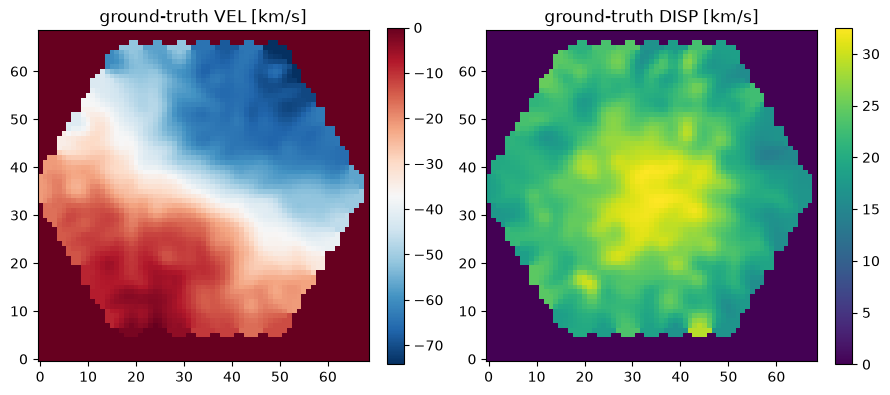

In [3]:
rss_path, maps_path = available[0]
maps = read_mangia_maps(maps_path)
print("maps:", sorted(maps.maps)[:10], "... (", len(maps.maps), "total)")
print("pixel_scale:", maps.pixel_scale, " redshift:", maps.redshift)
print("psf_fwhm:", maps.psf_fwhm, " fov:", maps.fov)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
im0 = axes[0].imshow(maps.maps["VEL"], origin="lower", cmap="RdBu_r")
axes[0].set_title("ground-truth VEL [km/s]")
fig.colorbar(im0, ax=axes[0], fraction=0.046)
im1 = axes[1].imshow(maps.maps["DISP"], origin="lower", cmap="viridis")
axes[1].set_title("ground-truth DISP [km/s]")
fig.colorbar(im1, ax=axes[1], fraction=0.046)
fig.tight_layout()

## 3. The "rss" product: real per-fibre flux + positions

`read_mangia_rss` parses the primary flux array (`(n_wave, n_fiber)`, a
real wavelength grid), the `Gas emission` extension, each fibre's real
sky position (`x_ifu`/`y_ifu`), and the same 41 ground-truth properties
as `maps`, here per fibre rather than per spaxel.

flux shape (n_wave, n_fiber): (6603, 381)
wavelength range: 3749.0 Angstrom - 10351.0 Angstrom
flux_unit: 1e-16 erg / (Angstrom s cm2)  psf_fwhm: 1.43 arcsec


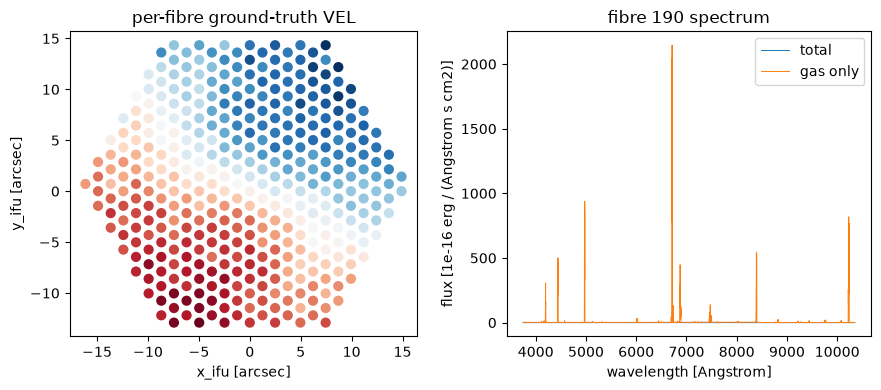

In [4]:
rss = read_mangia_rss(rss_path)
print("flux shape (n_wave, n_fiber):", rss.flux.shape)
print("wavelength range:", rss.wavelength[0], "-", rss.wavelength[-1])
print("flux_unit:", rss.flux_unit, " psf_fwhm:", rss.psf_fwhm)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
x_fib = rss.x_fiber.to_value(u.arcsec)
y_fib = rss.y_fiber.to_value(u.arcsec)
axes[0].scatter(x_fib, y_fib, c=rss.fiber_maps["VEL"], cmap="RdBu_r", s=40)
axes[0].set_xlabel("x_ifu [arcsec]")
axes[0].set_ylabel("y_ifu [arcsec]")
axes[0].set_title("per-fibre ground-truth VEL")
axes[0].set_aspect("equal")

mid_fiber = rss.flux.shape[1] // 2
wave = rss.wavelength.to_value(u.AA)
axes[1].plot(wave, rss.flux[:, mid_fiber], lw=0.7, label="total")
axes[1].plot(wave, rss.flux_gas[:, mid_fiber], lw=0.7, label="gas only")
axes[1].set_xlabel("wavelength [Angstrom]")
axes[1].set_ylabel(f"flux [{rss.flux_unit}]")
axes[1].set_title(f"fibre {mid_fiber} spectrum")
axes[1].legend()
fig.tight_layout()

## 4. Validating the regridder against ground truth

The real check: regrid the **rss** file's per-fibre ground-truth `VEL`/
`DISP` the same way `regrid_rss_to_cube` regrids flux, onto the matching
**maps** file's own spatial grid, and compare against that file's own
official, pre-gridded `VEL`/`DISP` for the *same* galaxy. Both sides start
from the same simulation ground truth, so this isolates the regridding
geometry -- no spectral fitting involved.

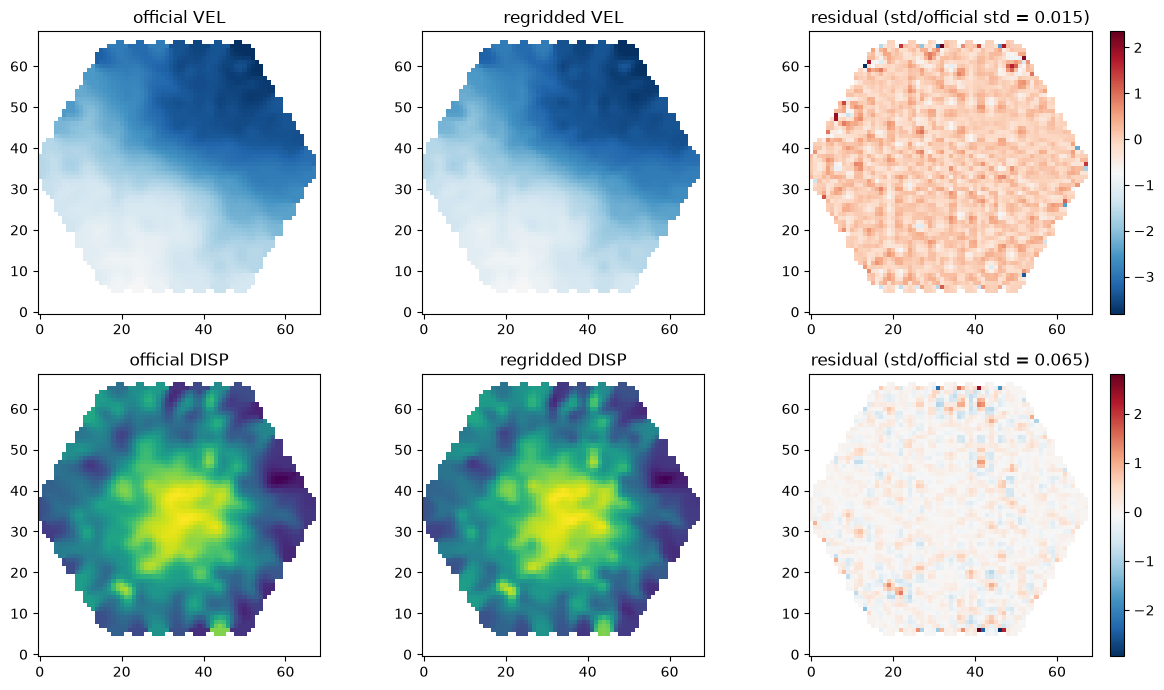

In [5]:
def validate_pair(rss_path, maps_path):
    maps = read_mangia_maps(maps_path)
    rss = read_mangia_rss(rss_path)
    ny, nx = maps.maps["VEL"].shape
    out = {}
    for name in ("VEL", "DISP"):
        regridded = regrid_fibers_to_grid(
            rss.x_fiber,
            rss.y_fiber,
            rss.fiber_maps[name],
            pixel_scale=maps.pixel_scale,
            nx=nx,
            ny=ny,
            kernel_fwhm=rss.psf_fwhm,
        )
        official = maps.maps[name]
        in_fov = official != 0.0
        resid = regridded[in_fov] - official[in_fov]
        scale = np.std(official[in_fov])
        ratio = float(np.std(resid) / scale) if scale > 0 else np.nan
        out[name] = (regridded, official, in_fov, ratio)
    return out


result = validate_pair(rss_path, maps_path)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for row, name in enumerate(("VEL", "DISP")):
    regridded, official, in_fov, ratio = result[name]
    # regrid_fibers_to_grid has no fibre-bundle footprint mask -- it
    # extrapolates (increasingly unreliably) outside real fibre coverage,
    # so mask display to the official map's own footprint, matching the
    # comparison the quoted ratio is actually computed over.
    regridded_masked = np.where(in_fov, regridded, np.nan)
    official_masked = np.where(in_fov, official, np.nan)
    vmax = np.nanmax(np.abs(official_masked))
    if name == "VEL":
        kw = dict(origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    else:
        kw = dict(origin="lower", cmap="viridis")
    axes[row, 0].imshow(official_masked, **kw)
    axes[row, 0].set_title(f"official {name}")
    axes[row, 1].imshow(regridded_masked, **kw)
    axes[row, 1].set_title(f"regridded {name}")
    resid_masked = np.where(in_fov, regridded - official, np.nan)
    im = axes[row, 2].imshow(resid_masked, origin="lower", cmap="RdBu_r")
    axes[row, 2].set_title(f"residual (std/official std = {ratio:.3f})")
    fig.colorbar(im, ax=axes[row, 2], fraction=0.046)
fig.tight_layout()

## 5. Sweep across the fetched sample

The same check across all ten fetched galaxies -- the regridder's actual
validation isn't one lucky galaxy, it's consistency across a real sample
(and the natural next step, per the project's own plan, is a larger one).

In [6]:
print(f"{'galaxy':30s} {'VEL ratio':>10s} {'DISP ratio':>10s}")
for rss_path, maps_path in available:
    res = validate_pair(rss_path, maps_path)
    print(f"{rss_path.stem:30s} {res['VEL'][3]:10.3f} {res['DISP'][3]:10.3f}")

galaxy                          VEL ratio DISP ratio
TNG50-97-664052-0-127.cube_RSS      0.015      0.065
TNG50-96-708947-0-127.cube_RSS      0.140      0.087


TNG50-97-708957-0-127.cube_RSS      0.032      0.079
TNG50-93-463010-0-127.cube_RSS      0.029      0.028
TNG50-97-468988-0-127.cube_RSS      0.104      0.126


TNG50-96-679529-0-127.cube_RSS      0.043      0.113
TNG50-97-650588-0-127.cube_RSS      0.316      0.656
TNG50-96-387721-2-127.cube_RSS      0.013      0.073


## 6. Exploratory: kino's own moment extraction on a regridded flux cube

This goes one step further: regrid the **gas-only** flux (`rss.flux_gas`,
to isolate emission-line kinematics from the stellar continuum), crop to
redshifted Halpha, and run the *same* `kino.analysis.moments.
compute_moment_maps` used on kino's own forward-modelled cubes elsewhere
in the notebooks. **This is exploratory, not a validated result** -- real
mock spectra are continuum+line, not the single isolated emission line
`compute_moment_maps` is designed for, and the fibre PSF/kernel choice
here is the same simplified one `regrid_rss_to_cube` always uses.

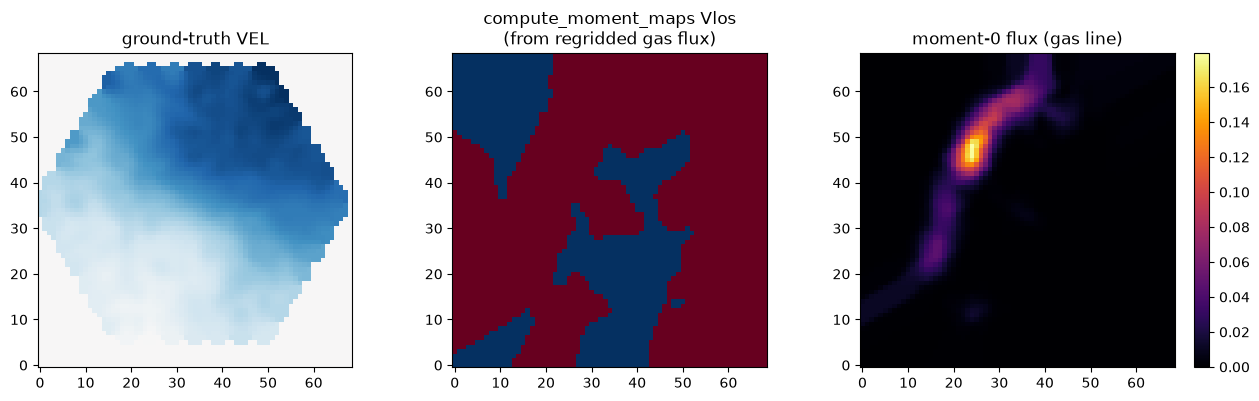

In [7]:
HALPHA_REST = 6562.8 * u.AA
z = maps.redshift
observed_halpha = HALPHA_REST * (1 + z)

ny, nx = maps.maps["VEL"].shape
gas_rss = read_mangia_rss(rss_path)
cube = regrid_rss_to_cube(gas_rss, nx=nx, ny=ny, pixel_scale=maps.pixel_scale)
# swap in the gas-only flux (regrid_rss_to_cube regrids total flux by default)
cube.flux = regrid_fibers_to_grid(
    gas_rss.x_fiber,
    gas_rss.y_fiber,
    gas_rss.flux_gas,
    pixel_scale=maps.pixel_scale,
    nx=nx,
    ny=ny,
    kernel_fwhm=gas_rss.psf_fwhm,
)

window = crop_to_line(cube, center=observed_halpha, half_width=20 * u.AA)
moments = compute_moment_maps(
    window, line_wavelength=HALPHA_REST, snr_threshold=0.0, check_window=False
)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
vmax = np.nanmax(np.abs(maps.maps["VEL"]))
axes[0].imshow(maps.maps["VEL"], origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axes[0].set_title("ground-truth VEL")
axes[1].imshow(moments.vlos, origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axes[1].set_title("compute_moment_maps Vlos\n(from regridded gas flux)")
im2 = axes[2].imshow(moments.flux, origin="lower", cmap="inferno")
axes[2].set_title("moment-0 flux (gas line)")
fig.colorbar(im2, ax=axes[2], fraction=0.046)
fig.tight_layout()

## What's next

- **Scale to a larger sample** (per the project's own plan) -- `kino.io.
  download.fetch_mangia_members` is efficient for this (one streaming
  pass per archive regardless of sample size).
- The regridder is a simplified Gaussian-kernel ("drizzle"-like) scheme,
  not a flux-conserving reproduction of the real MaNGA DRP cubing
  algorithm or MaNGIA's own generator -- revisit if Section 6's
  exploratory comparison needs to become a validated result.
- Confirm whether `x_ifu`/`y_ifu` follow KINO's East-of-North sky
  convention before trusting any PA-dependent science from a regridded
  cube -- not yet checked (see `kino/io/manga.py`'s module docstring).
- iMaNGA (a different team's TNG50 mock-MaNGA catalogue, confusingly
  similar name) is untouched.
- The real validation payoff (`TEST_DATA.md` Tier B, "most valuable"):
  wire a regridded real MaNGIA cube into `kino.analysis.injection`/
  `kino.analysis.model_compare` once real data replaces synthetic mocks
  there too.